# IAU – Fáza 1: Prieskumná analýza

Dataset: **111**

Stanislav Shkira – **50 %** (načítanie, integrácia a čistenie dát).  
Pryshedko Sofiia – **50 %** (EDA, grafy, hypotézy a štatistické testy).

Cieľom je preskúmať dáta a súvislosti s premennou `failure`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

units_raw = pd.read_csv("data/units.csv")
gateways_raw = pd.read_csv("data/gateways.csv", sep=";")
readings_raw = pd.read_csv("data/readings.csv", sep="\t")

senzory = ["motorCurrent", "filter_dp", "oil_temperature",
           "pressureReservoir", "workingPressure", "pressure_oil",
           "rms_vibration", "Flowmeter", "humidity_intake",
           "ambient_noise", "bearingTemp", "auxCurrent"]

## 1.1 Základný opis dát

### A. Súbory a štruktúra

- `units.csv`: údaje o jednotkách, kľúč `id_unit`.
- `gateways.csv`: údaje o bránach, kľúč `gateway_id`.
- `readings.csv`: merania senzorov, čas `tsCycle` a cieľ `failure`.

In [3]:
for nazov, tabulka in [("units", units_raw),
                       ("gateways", gateways_raw),
                       ("readings", readings_raw)]:
    print(nazov, "– riadky:", tabulka.shape[0], "stĺpce:", tabulka.shape[1])
    prehlad = pd.DataFrame({"Typ": tabulka.dtypes,
                           "Chýba": tabulka.isna().sum(),
                           "Unikátne": tabulka.nunique()})
    display(prehlad)
    display(tabulka.head(2))

units – riadky: 2000 stĺpce: 13


,Typ,Chýba,Unikátne
operatorOwner,object,0,40
install_region,object,0,56
modelCode,object,0,4
serviceHours,float64,100,1865
commission_year,int64,0,13
Manufacturer,object,0,40
fleetCode,object,0,5
idDepot,int64,0,120
id_unit,int64,0,2000
duty_class,object,0,20


,operatorOwner,install_region,modelCode,serviceHours,commission_year,Manufacturer,fleetCode,idDepot,id_unit,duty_class,overhaulLast,serialNumber,lineCode
0,Hoffmann,Port Petermouth,APU-12,8266.1,2022,Antunes Reis e Filhos,FD,94,1,heavy,15 Oct 2020,BA-8827-44060,L5
1,Schönland KG,Jessen,APU-15,11830.9,2021,Hendriks KG,FD,75,2,normal,2018-01-27,TO-4910-61374,L3


gateways – riadky: 16000 stĺpce: 10


,Typ,Chýba,Unikátne
technician,object,0,120
Vendor,object,0,40
gateway_id,object,0,16000
signal_dbm,float64,0,587
idDepot,int64,0,120
id_unit,float64,14000,2000
date_install,object,0,9754
firmware_version,object,0,3
mac_address,object,0,16000
seenLast,object,0,1600


,technician,Vendor,gateway_id,signal_dbm,idDepot,id_unit,date_install,firmware_version,mac_address,seenLast
0,Dr. Roswita Kaul B.Eng.,Hecker KG,GW-00000,-79.0,7,2000.0,"11/14/2019, 00:00:00",v2.7.0,06:a7:0f:a5:e9:11,28 Apr 2024
1,Ing. Leander Junck MBA.,Vogt,GW-00001,-77.5,55,806.0,2024-12-22,v3.4.1,66:f2:52:27:a3:8b,2024/12/27


readings – riadky: 14004 stĺpce: 15


,Typ,Chýba,Unikátne
id_unit,object,0,2110
tsCycle,object,0,4476
motorCurrent,float64,0,13651
filter_dp,float64,583,13181
oil_temperature,float64,0,13729
pressureReservoir,float64,0,13362
workingPressure,float64,0,13340
pressure_oil,float64,0,13340
rms_vibration,float64,570,13032
Flowmeter,float64,0,13719


,id_unit,tsCycle,motorCurrent,filter_dp,oil_temperature,pressureReservoir,workingPressure,pressure_oil,rms_vibration,Flowmeter,humidity_intake,ambient_noise,bearingTemp,auxCurrent,failure
0,U00252,"03/28/2023, 22:27:00",2.96108,11.83959,50.24491,9.46308,9.51648,4.91870,3.25376,29.41640,42.70893,74.98079,77.07824,1.67655,0
1,U00563,06 Oct 2023,6.12798,50.43475,70.13202,8.63538,8.45419,4.07649,3.86850,29.87924,71.07291,64.65937,76.42799,2.33964,0


### Príprava dát

Odstránime presné duplikáty a `-999` v teplote nahradíme chýbajúcou hodnotou. Zjednotíme ID, dátumy a jasné skratky `duty_class`. Význam `1/2/3` a `med` nie je doložený.

In [4]:
units = units_raw.copy()
gateways = gateways_raw.copy()
readings = readings_raw.drop_duplicates().copy()

units["id_unit"] = "U" + units["id_unit"].astype(str).str.zfill(5)
units["duty_class"] = units["duty_class"].str.strip().str.lower()
units["duty_class"] = units["duty_class"].replace({"l": "light", "n": "normal", "h": "heavy"})

readings["tsCycle"] = pd.to_datetime(readings["tsCycle"], format="mixed", errors="coerce")
units["overhaulLast"] = pd.to_datetime(units["overhaulLast"], format="mixed", errors="coerce")
gateways["date_install"] = pd.to_datetime(gateways["date_install"], format="mixed", errors="coerce")
gateways["seenLast"] = pd.to_datetime(gateways["seenLast"], format="mixed", errors="coerce")

print("Odstránené duplikáty:", len(readings_raw) - len(readings))
print("Hodnoty -999:", (readings["oil_temperature"] == -999).sum())
readings.loc[readings["oil_temperature"] == -999, "oil_temperature"] = np.nan
print("Neplatné dátumy meraní:", readings["tsCycle"].isna().sum())
print("duty_class:", units["duty_class"].unique())

Odstránené duplikáty: 207
Hodnoty -999: 37
Neplatné dátumy meraní: 0
duty_class: ['heavy' 'normal' '3' 'med' 'light' '2' '1']


### Integrácia

Brány pripojíme iba cez známe `id_unit`. Spojenie cez samotné depo by násobilo merania. Merania bez jednotky ponecháme s prázdnymi metadátami.

In [5]:
brany = gateways[gateways["id_unit"].notna()].copy()
brany["id_unit"] = "U" + brany["id_unit"].astype(int).astype(str).str.zfill(5)
brany = brany.rename(columns={"idDepot": "idDepot_gateway"})

print("Brány s jednotkou:", len(brany))
print("Brány bez jednotky:", gateways["id_unit"].isna().sum())
print("Duplicity ID jednotiek:", units["id_unit"].duplicated().sum())
print("Duplicity ID v priradených bránach:", brany["id_unit"].duplicated().sum())

data = readings.merge(units, on="id_unit", how="left", validate="many_to_one")
data = data.merge(brany[["id_unit", "gateway_id", "idDepot_gateway",
                        "signal_dbm", "date_install", "seenLast"]],
                  on="id_unit", how="left", validate="many_to_one")

print("Riadky pred/po spojení:", len(readings), len(data))
print("Merania bez jednotky:", (~readings["id_unit"].isin(units["id_unit"])).sum())

Brány s jednotkou: 2000
Brány bez jednotky: 14000
Duplicity ID jednotiek: 0
Duplicity ID v priradených bránach: 0
Riadky pred/po spojení: 13797 13797
Merania bez jednotky: 130


### B. Analýza 12 senzorov

Presné fyzikálne limity nie sú uvedené. Kontrolujeme rozsah, chýbajúce hodnoty a rozdelenia. Histogramy zobrazujú stredných 99 % hodnôt; tabuľka obsahuje všetky.

In [6]:
opis = readings[senzory].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
opis = opis.rename(columns={"count": "Počet", "mean": "Priemer", "std": "Odchýlka",
                            "min": "Minimum", "max": "Maximum"})
opis["Chýba"] = readings[senzory].isna().sum()
display(opis.round(3))

,Počet,Priemer,Odchýlka,Minimum,5%,25%,50%,75%,95%,Maximum,Chýba
motorCurrent,13797.0,5.243,2.900,0.000,2.488,3.713,5.063,6.581,8.266,99.000,0
filter_dp,13217.0,24.088,11.225,6.704,11.606,16.342,21.447,28.776,45.608,120.000,580
oil_temperature,13760.0,54.925,11.991,15.000,34.938,46.852,54.978,63.041,74.354,95.000,37
pressureReservoir,13797.0,8.701,0.604,6.500,7.703,8.292,8.695,9.114,9.707,10.500,0
workingPressure,13797.0,8.701,0.624,6.201,7.674,8.279,8.695,9.125,9.737,10.500,0
pressure_oil,13797.0,3.703,0.568,1.500,2.781,3.315,3.702,4.093,4.641,5.889,0
rms_vibration,13232.0,3.096,1.650,0.500,1.190,1.936,2.735,3.840,6.249,14.000,565
Flowmeter,13797.0,27.978,3.994,15.000,21.320,25.317,27.996,30.688,34.520,40.000,0
humidity_intake,13166.0,52.347,24.281,10.007,14.459,31.698,51.994,73.172,90.691,94.993,631
ambient_noise,13797.0,75.002,6.010,55.000,65.266,70.912,74.923,79.082,84.825,95.000,0


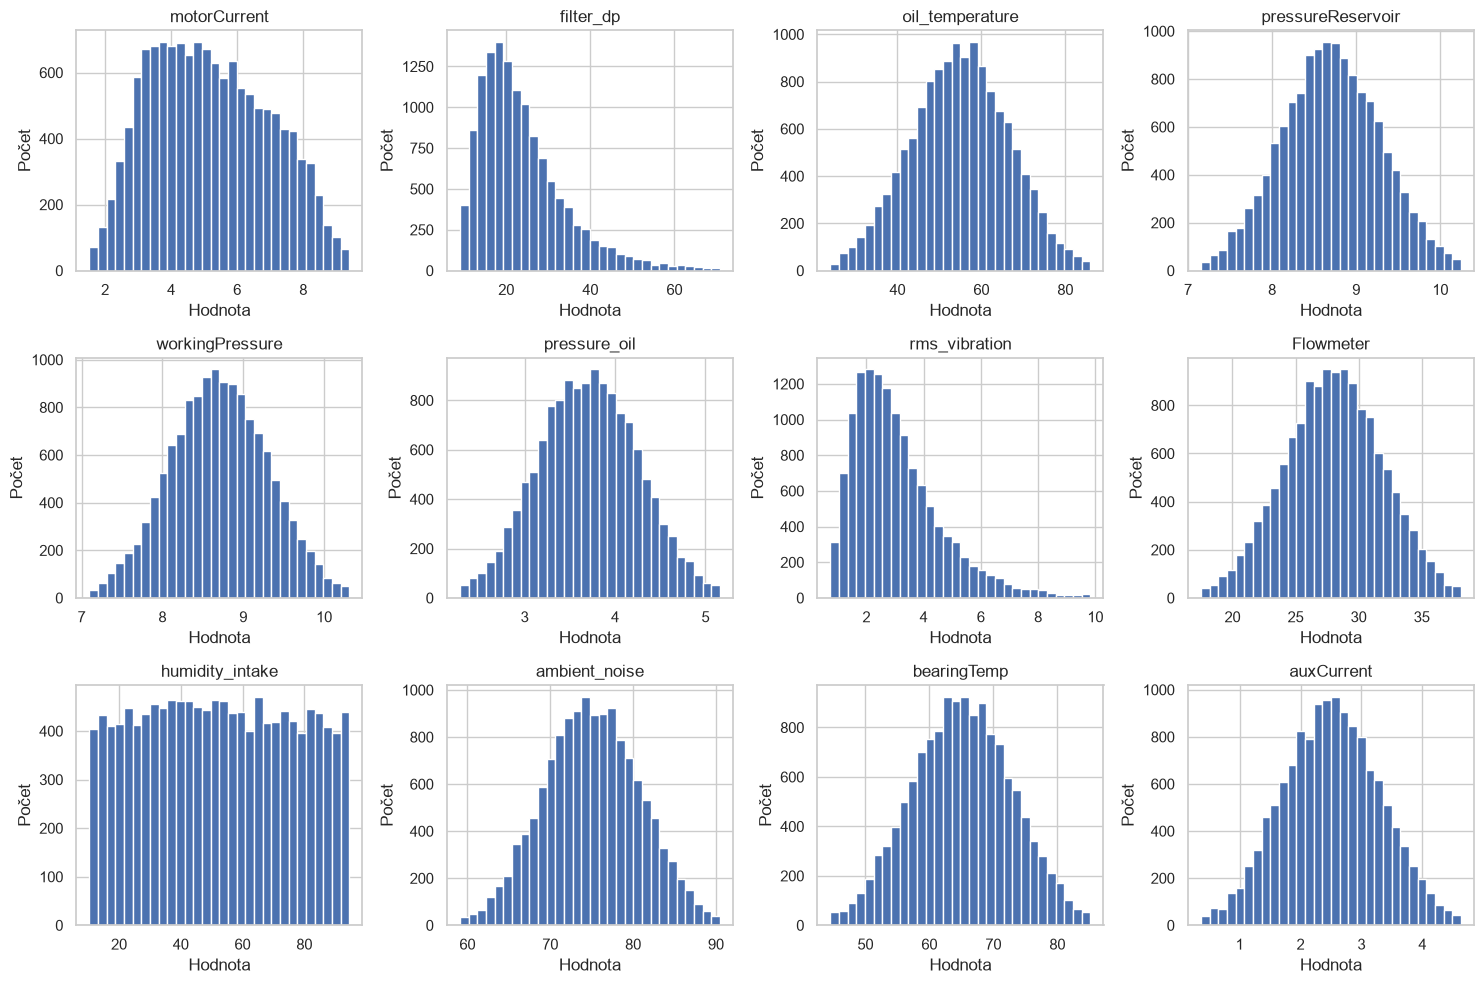

In [7]:
plt.figure(figsize=(15, 10))
for i, nazov in enumerate(senzory):
    plt.subplot(3, 4, i + 1)
    x = readings[nazov].dropna()
    x = x[x.between(x.quantile(0.005), x.quantile(0.995))]
    plt.hist(x, bins=30)
    plt.title(nazov)
    plt.xlabel("Hodnota")
    plt.ylabel("Počet")
plt.tight_layout()
plt.show()

`filter_dp` a `rms_vibration` majú pravostranný chvost. Tlakové senzory majú úzke rozdelenia. `humidity_intake` je približne rovnomerný. `motorCurrent=99` preveríme ako odľahlú hodnotu.

,Počet,Podiel_%
failure,,
0,12105,87.74
1,1692,12.26


failure obsahuje iba 0 a 1: True
Obdobie: 2023-01-01 00:00:00 – 2023-12-31 21:58:00


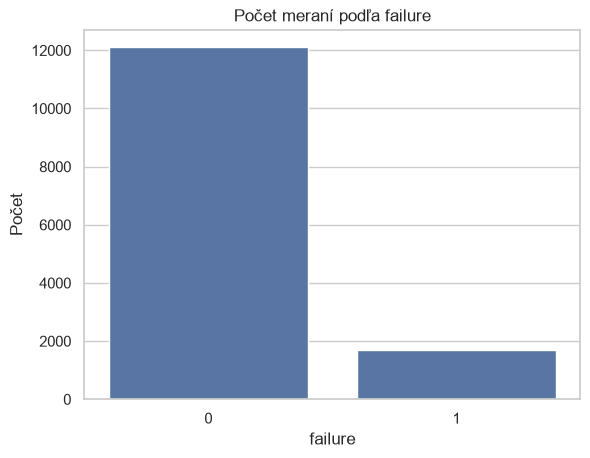

In [8]:
pocet = readings["failure"].value_counts().sort_index()
display(pd.DataFrame({"Počet": pocet, "Podiel_%": 100 * pocet / len(readings)}).round(2))
print("failure obsahuje iba 0 a 1:", readings["failure"].isin([0, 1]).all())
print("Obdobie:", readings["tsCycle"].min(), "–", readings["tsCycle"].max())

sns.countplot(data=readings, x="failure")
plt.title("Počet meraní podľa failure")
plt.ylabel("Počet")
plt.show()

### C. Vzťahy medzi senzormi

`pressureReservoir` a `workingPressure` silno korelujú (r ≈ 0,97). Pri modelovaní preveríme ich podobnú informáciu.

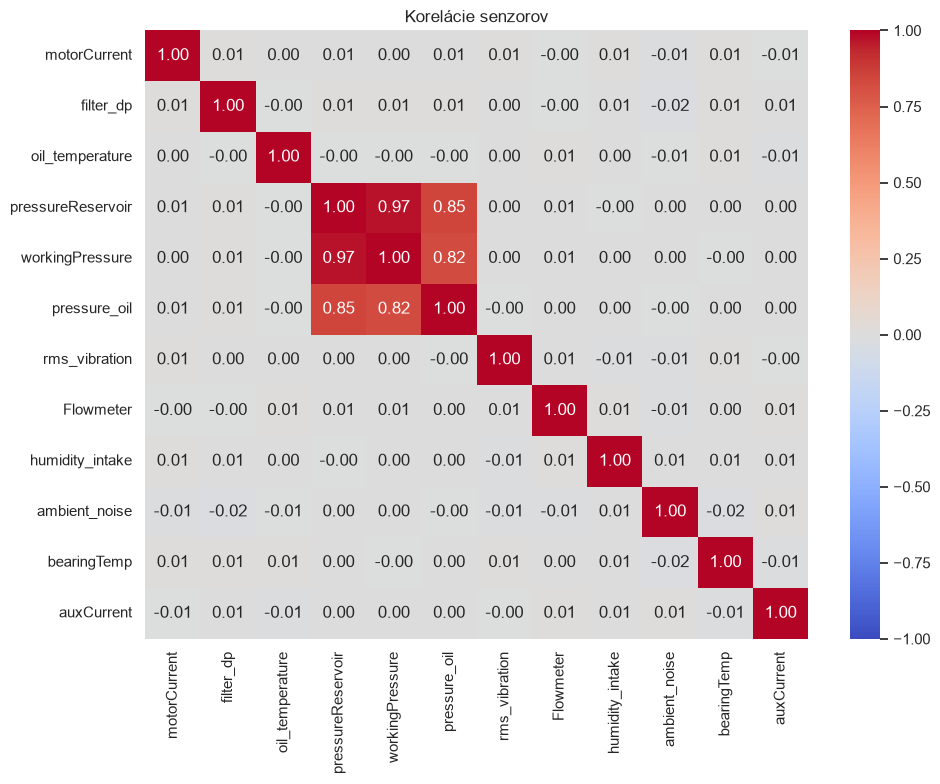

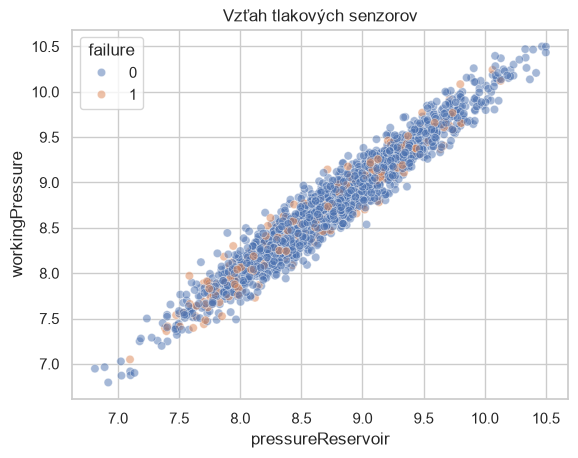

In [10]:
korelacia = readings[senzory].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(korelacia, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelácie senzorov")
plt.tight_layout()
plt.show()

vzorka = readings.sample(2000, random_state=111)
sns.scatterplot(data=vzorka, x="pressureReservoir", y="workingPressure", hue="failure", alpha=0.5)
plt.title("Vzťah tlakových senzorov")
plt.show()

### D. Vzťah k failure

Pri `failure=1` sú priemery `bearingTemp`, `filter_dp` a `rms_vibration` vyššie; `Flowmeter` je nižší. Boxploty skrývajú iba body odľahlých hodnôt.

,failure=0,failure=1,Rozdiel 1-0
motorCurrent,5.269,5.055,-0.214
filter_dp,23.634,28.075,4.440
oil_temperature,54.980,54.531,-0.448
pressureReservoir,8.717,8.590,-0.127
workingPressure,8.717,8.586,-0.131
pressure_oil,3.715,3.618,-0.097
rms_vibration,3.066,3.362,0.296
Flowmeter,28.029,27.613,-0.416
humidity_intake,52.436,51.708,-0.728
ambient_noise,74.982,75.146,0.164


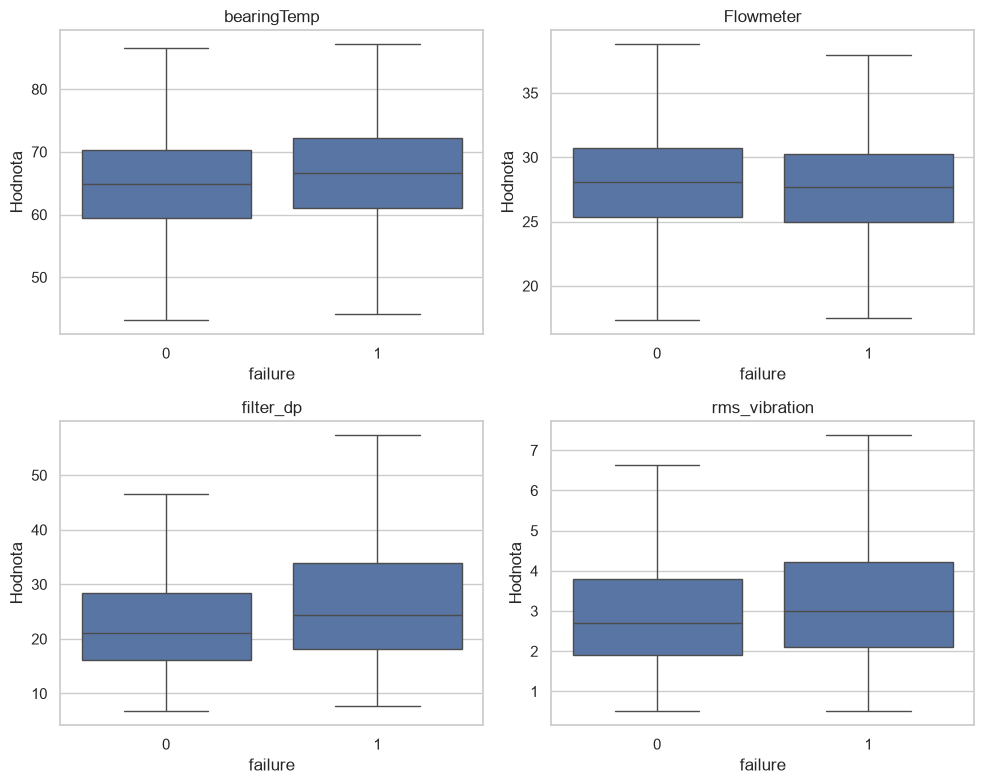

In [11]:
priemery = readings.groupby("failure")[senzory].mean().T
priemery.columns = ["failure=0", "failure=1"]
priemery["Rozdiel 1-0"] = priemery["failure=1"] - priemery["failure=0"]
display(priemery.round(3))

plt.figure(figsize=(10, 8))
for i, nazov in enumerate(["bearingTemp", "Flowmeter", "filter_dp", "rms_vibration"]):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(data=readings, x="failure", y=nazov, showfliers=False)
    plt.title(nazov)
    plt.ylabel("Hodnota")
plt.tight_layout()
plt.show()

### E. Prvé rozhodnutia

Preskúmame najmä `bearingTemp`, `Flowmeter`, `filter_dp` a `rms_vibration`. Záznamy spojíme podľa jednotky. Neskoršie dátumy opráv a brán nemožno bez časovej kontroly použiť na predikciu starších meraní.

## 1.2 Problémy a čistenie dát

### A. Chýbajúce hodnoty

`filter_dp` a `rms_vibration` chýbajú častejšie pri poruche. Zatiaľ ich nevypĺňame. Pre testy volíme úplné senzory; imputáciu nastavíme vo fáze 2.

In [12]:
for nazov, tabulka in [("units", units_raw), ("gateways", gateways_raw), ("readings", readings_raw)]:
    chyba = tabulka.isna().sum()
    print(nazov)
    display(chyba[chyba > 0].to_frame("Chýba"))

chyba_podla_failure = readings[senzory].isna().groupby(readings["failure"]).mean().T * 100
chyba_podla_failure.columns = ["failure=0 (%)", "failure=1 (%)"]
display(chyba_podla_failure.round(2))

units


,Chýba
serviceHours,100


gateways


,Chýba
id_unit,14000


readings


,Chýba
filter_dp,583
rms_vibration,570
humidity_intake,643


,failure=0 (%),failure=1 (%)
motorCurrent,0.00,0.00
filter_dp,1.96,20.27
oil_temperature,0.29,0.12
pressureReservoir,0.00,0.00
workingPressure,0.00,0.00
pressure_oil,0.00,0.00
rms_vibration,2.09,18.44
Flowmeter,0.00,0.00
humidity_intake,4.55,4.73
ambient_noise,0.00,0.00


### B. Správnosť a časové vzťahy

Neznáme jednotky a časové rozpory označíme, dátumy neodhadujeme. Rovnaký deň nemusí znamenať duplikát, pretože čas často nemá hodinu.

In [13]:
kontrola = pd.Series({
    "Merania bez jednotky": (~readings["id_unit"].isin(units["id_unit"])).sum(),
    "seenLast pred date_install": (gateways["seenLast"] < gateways["date_install"]).sum(),
    "Meranie pred rokom uvedenia": (data["commission_year"] > data["tsCycle"].dt.year).sum(),
    "Brána nainštalovaná až po meraní": (data["date_install"] > data["tsCycle"]).sum(),
    "Rozdielne depo jednotky a brány": (data.loc[data["idDepot_gateway"].notna(), "idDepot"] !=
                                       data.loc[data["idDepot_gateway"].notna(), "idDepot_gateway"]).sum()
})
display(kontrola.to_frame("Počet"))

kluce = readings.groupby(["id_unit", "tsCycle"]).size()
triedy = readings.groupby(["id_unit", "tsCycle"])["failure"].nunique()
print("Opakované ID a čas:", (kluce > 1).sum())
print("Z nich s rôznym failure:", (triedy > 1).sum())

,Počet
Merania bez jednotky,130
seenLast pred date_install,719
Meranie pred rokom uvedenia,363
Brána nainštalovaná až po meraní,1996
Rozdielne depo jednotky a brány,0


Opakované ID a čas: 74
Z nich s rôznym failure: 18


### C. Odľahlé hodnoty – dve metódy

V `motorCurrent` použijeme hranice Q1 − 1,5·IQR a Q3 + 1,5·IQR. Porovnáme odstránenie riadkov a nahradenie odľahlých hodnôt 5./95. percentilom.

In [14]:
x = readings["motorCurrent"]
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1
dolna = q1 - 1.5 * iqr
horna = q3 + 1.5 * iqr
odlahle = (x < dolna) | (x > horna)

print("Hranice:", round(dolna, 3), round(horna, 3))
print("Odľahlé hodnoty:", odlahle.sum())
display(readings.loc[odlahle, ["id_unit", "motorCurrent", "failure"]])

Hranice: -0.589 10.882
Odľahlé hodnoty: 8


,id_unit,motorCurrent,failure
412,U01757,99.0,1
4028,U00720,99.0,0
4682,U00998,99.0,1
5035,U01140,99.0,0
8368,U01658,99.0,0
8534,U00970,99.0,0
10031,U00484,99.0,0
10389,U00867,99.0,1


,Metóda,Riadky,Poruchy,Priemer motorCurrent
0,Pôvodné,13797,1692,5.243
1,Odstránenie,13789,1689,5.188
2,Nahradenie,13797,1692,5.190


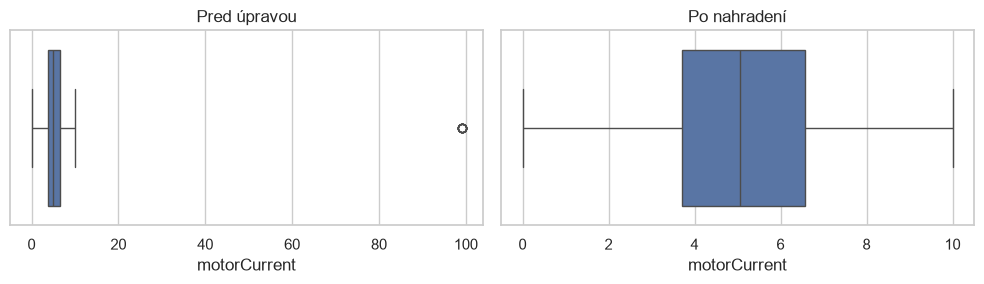

In [13]:
bez_odlahlych = readings[~odlahle].copy()
upravene = readings.copy()
p05 = x.quantile(0.05)
p95 = x.quantile(0.95)
upravene.loc[odlahle, "motorCurrent"] = x[odlahle].clip(p05, p95)

porovnanie = pd.DataFrame({
    "Metóda": ["Pôvodné", "Odstránenie", "Nahradenie"],
    "Riadky": [len(readings), len(bez_odlahlych), len(upravene)],
    "Poruchy": [readings["failure"].sum(), bez_odlahlych["failure"].sum(), upravene["failure"].sum()],
    "Priemer motorCurrent": [readings["motorCurrent"].mean(), bez_odlahlych["motorCurrent"].mean(), upravene["motorCurrent"].mean()]
})
display(porovnanie.round(3))

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
sns.boxplot(x=readings["motorCurrent"])
plt.title("Pred úpravou")
plt.subplot(1, 2, 2)
sns.boxplot(x=upravene["motorCurrent"])
plt.title("Po nahradení")
plt.tight_layout()
plt.show()

IQR našiel 8 hodnôt `99`, z toho 3 pri poruche. Nahradenie zachová všetky riadky, preto ho volíme ako skúšobnú úpravu. Pôvodné hodnoty zostávajú v `readings`.

## 1.3 Hypotézy a štatistické testy

H1: `bearingTemp` je pri poruche vyšší. H0: rozdiel nie je kladný.  
H2: `Flowmeter` je pri poruche nižší. H0: rozdiel nie je záporný.

Použijeme priemery oboch stavov v rovnakej jednotke a párový t-test. Vyberieme známe jednotky uvedené najneskôr v roku 2023. Predpokladáme nezávislosť jednotiek. Pre dva testy použijeme α = 0,025. Výsledky sú prieskumné.

In [15]:
platne_id = units.loc[units["commission_year"] <= 2023, "id_unit"]
test_data = readings[readings["id_unit"].isin(platne_id)]
priemery_stavov = test_data.groupby(["id_unit", "failure"])[["bearingTemp", "Flowmeter"]].mean()

teplota = priemery_stavov["bearingTemp"].unstack().dropna()
prietok = priemery_stavov["Flowmeter"].unstack().dropna()
rozdiel_teploty = teplota[1] - teplota[0]
rozdiel_prietoku = prietok[1] - prietok[0]

test1 = stats.ttest_rel(teplota[1], teplota[0], alternative="greater")
test2 = stats.ttest_rel(prietok[1], prietok[0], alternative="less")

vysledky = pd.DataFrame({
    "Senzor": ["bearingTemp", "Flowmeter"],
    "Počet párov": [len(teplota), len(prietok)],
    "Priemerný rozdiel 1-0": [rozdiel_teploty.mean(), rozdiel_prietoku.mean()],
    "p-hodnota": [f"{test1.pvalue:.3g}", f"{test2.pvalue:.3g}"]
})
display(vysledky)

,Senzor,Počet párov,Priemerný rozdiel 1-0,p-hodnota
0,bearingTemp,1022,2.066577,1.12e-16
1,Flowmeter,1022,-0.407953,0.000478


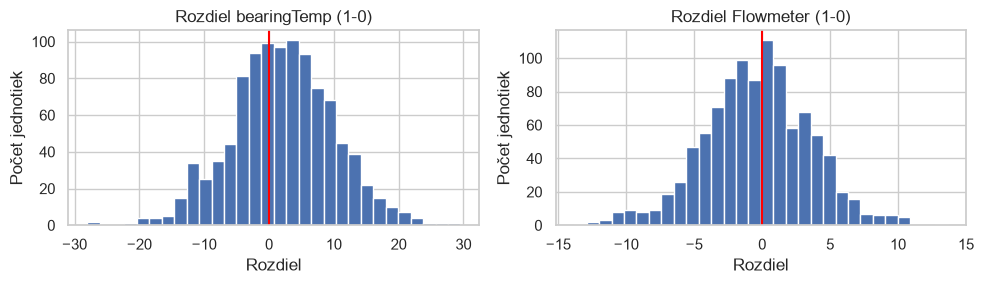

In [16]:
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(rozdiel_teploty, bins=30)
plt.axvline(0, color="red")
plt.title("Rozdiel bearingTemp (1-0)")
plt.xlabel("Rozdiel")
plt.ylabel("Počet jednotiek")

plt.subplot(1, 2, 2)
plt.hist(rozdiel_prietoku, bins=30)
plt.axvline(0, color="red")
plt.title("Rozdiel Flowmeter (1-0)")
plt.xlabel("Rozdiel")
plt.ylabel("Počet jednotiek")
plt.tight_layout()
plt.show()

Pri poruche je `bearingTemp` vyšší asi o 2,07 a `Flowmeter` nižší asi o 0,41. Obe p-hodnoty sú pod 0,025. Rozdiely sú približne symetrické, počet párov je 1022.

### Štatistická sila

Overíme silu pre efekty d = 0,05; 0,1; 0,2. Sú to štatistické orientačné hodnoty. Za dostatočnú považujeme silu aspoň 80 %.

In [17]:
n = min(len(teplota), len(prietok))
hranica = stats.t.ppf(0.975, n - 1)
for efekt in [0.05, 0.1, 0.2]:
    posun = efekt * np.sqrt(n)
    sila = stats.nct.sf(hranica, n - 1, posun)
    print("Efekt d =", efekt, "– sila:", round(100 * sila, 5), "%")

Efekt d = 0.05 – sila: 35.8291 %
Efekt d = 0.1 – sila: 89.13801 %
Efekt d = 0.2 – sila: 99.99952 %


Sila pre d = 0,1 je približne 89 %, pre d = 0,2 nad 99 %. Pre veľmi malý efekt d = 0,05 nestačí.

## Záver

Dáta možno spracovať po zjednotení ID a dátumov. Odstránili sme 207 duplikátov, označili chýbajúce a podozrivé hodnoty a porovnali dve úpravy odľahlých hodnôt. Nejasné časové vzťahy treba overiť. Ďalej pripravíme imputáciu a časovo správne prediktory.